# 03 · Strategy comparison (E2 multi-seat, E3 low contention)

Compares the correct strategies on cost: deadlocks and aborts under overlapping requests (E2), and latency and throughput when requests never collide (E3). Includes two **ablations** (remove one ingredient of a strategy and measure the effect) and the **computational** cost.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC, RES = ROOT / "data/raw", ROOT / "data/processed", ROOT / "experiments/results"
LOGS, CONFIG = ROOT / "experiments/logs", ROOT / "experiments/configs/experiments.json"

def load_events(run):
    """One row per logged event (op = one transaction attempt, trial = one trial)."""
    return pd.read_json(RAW / run / "events.jsonl", lines=True)

ORDER = ["naive", "conditional_update", "pessimistic_sorted", "pessimistic_unordered",
         "optimistic_version", "serializable", "advisory_lock"]
COLORS = dict(zip(ORDER, ["#d92d20", "#F84464", "#2e90fa", "#7a5af8", "#12b76a", "#f79009", "#667085"]))
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
from statsmodels.stats.multitest import multipletests

In [2]:
neon = load_events("main-neon")
ops = neon[(neon.type == "op") & (~neon.warmup.fillna(False).astype(bool))]
T = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]

C:\Users\user\AppData\Local\Temp\ipykernel_22508\690530047.py:2: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  ops = neon[(neon.type == "op") & (~neon.warmup.fillna(False).astype(bool))]
C:\Users\user\AppData\Local\Temp\ipykernel_22508\690530047.py:3: Pandas4Warning: 'bool' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  T = neon[(neon.type == "trial") & (~neon.warmup.fillna(False).astype(bool))]


## E2 — overlapping three-seat requests (c = 16)

In [3]:
e2o = ops[ops.exp == "E2"]
mix = pd.crosstab(e2o.strategy, e2o.outcome).reindex([s for s in ORDER if s in e2o.strategy.unique()])
mix["seats_sold_per_trial"] = T[T.exp == "E2"].groupby("strategy").claimedSeats.mean().round(2)
mix["double_bookings"] = T[T.exp == "E2"].groupby("strategy").doubleBookings.sum()
mix

outcome,conflict,deadlock,serialization_failure,success,seats_sold_per_trial,double_bookings
strategy,,,,,,
naive,0,0,0,240,9.93,571.0
conditional_update,206,0,0,34,6.80,0.0
pessimistic_sorted,203,0,0,37,7.40,0.0
pessimistic_unordered,113,93,0,34,6.80,0.0
optimistic_version,204,0,0,36,7.20,0.0
serializable,0,0,225,15,3.00,0.0


## Ablations
* **Lock ordering** — `pessimistic_sorted` vs `pessimistic_unordered` differ only in whether rows are locked in a consistent order.
* **Isolation level** — `naive` vs `serializable` run identical code; only the isolation level changes.

In [4]:
def rate(df, s, outcome):
    d = df[df.strategy == s]
    return (d.outcome == outcome).mean()
abl = pd.DataFrame([
    ["lock ordering", "sorted → unordered", "deadlock rate", rate(e2o, "pessimistic_sorted", "deadlock"), rate(e2o, "pessimistic_unordered", "deadlock")],
    ["isolation level", "READ COMMITTED → SERIALIZABLE", "double bookings / trial",
     T[(T.exp == "E2") & (T.strategy == "naive")].doubleBookings.mean(), T[(T.exp == "E2") & (T.strategy == "serializable")].doubleBookings.mean()],
    ["isolation level", "READ COMMITTED → SERIALIZABLE", "abort rate", 0.0, rate(e2o, "serializable", "serialization_failure")],
], columns=["ablation", "change", "metric", "before", "after"])
abl.round(3)

,ablation,change,metric,before,after
0,lock ordering,sorted → unordered,deadlock rate,0.000,0.388
1,isolation level,READ COMMITTED → SERIALIZABLE,double bookings / trial,38.067,0.000
2,isolation level,READ COMMITTED → SERIALIZABLE,abort rate,0.000,0.938


## E3 — latency without collisions (Kruskal–Wallis, then Mann–Whitney vs. conditional UPDATE with Holm correction)
Cliff's δ = 2U/(n₁n₂) − 1, the probability that a draw from one strategy is slower minus the probability it is faster.

In [5]:
e3 = ops[(ops.exp == "E3") & (ops.outcome == "success")]
res = []
for c in sorted(int(v) for v in e3.c.unique()):
    groups = {s: g.latencyMs.values for s, g in e3[e3.c == c].groupby("strategy")}
    H, pkw = stats.kruskal(*groups.values())
    print(f"c = {c:2d}: Kruskal-Wallis H = {H:.2f}, p = {pkw:.2e}")
    ref = groups["conditional_update"]
    for s, x in groups.items():
        if s == "conditional_update":
            continue
        U, p = stats.mannwhitneyu(x, ref, alternative="two-sided", use_continuity=True, method="asymptotic")
        res.append((c, s, np.median(x), np.median(ref), U, p, 2 * U / (len(x) * len(ref)) - 1))
mw = pd.DataFrame(res, columns=["c", "strategy", "median_ms", "median_cond_ms", "U", "p", "cliffs_delta"])
mw["p_holm"] = np.concatenate([multipletests(g.p, method="holm")[1] for _, g in mw.groupby("c")])
mw.round({"median_ms": 1, "median_cond_ms": 1, "cliffs_delta": 3})

c =  1: Kruskal-Wallis H = 153.53, p = 2.36e-31
c = 16: Kruskal-Wallis H = 1936.15, p = 0.00e+00


,c,strategy,median_ms,median_cond_ms,U,p,cliffs_delta,p_holm
0,1,advisory_lock,564.9,365.5,900.0,3.019859e-11,1.000,1.509930e-10
1,1,naive,391.6,365.5,792.0,4.444048e-07,0.760,4.444048e-07
2,1,optimistic_version,473.5,365.5,900.0,3.019859e-11,1.000,1.509930e-10
3,1,pessimistic_sorted,409.8,365.5,890.0,8.152745e-11,0.978,2.445823e-10
4,1,serializable,401.0,365.5,877.0,2.871585e-10,0.949,5.743170e-10
5,16,advisory_lock,5613.8,344.4,230381.0,2.200477e-158,1.000,1.100239e-157
6,16,naive,434.7,344.4,225986.0,1.114634e-146,0.962,2.229267e-146
7,16,optimistic_version,441.1,344.4,227829.0,1.563822e-151,0.978,6.255289e-151
8,16,pessimistic_sorted,444.8,344.4,225301.0,6.768733e-145,0.956,6.768733e-145
9,16,serializable,438.6,344.4,216134.0,7.195391e-147,0.975,2.158617e-146


## Throughput with bootstrap confidence intervals

In [6]:
rows = []
for (s, c), g in T[T.exp == "E3"].groupby(["strategy", "c"]):
    thr = (g.successes / g.makespanMs * 1000).values
    bs = stats.bootstrap((thr,), np.mean, confidence_level=0.95, method="percentile", n_resamples=5000, random_state=1)
    rows.append((s, c, thr.mean(), *bs.confidence_interval))
thr = pd.DataFrame(rows, columns=["strategy", "c", "holds_per_s", "ci_low", "ci_high"]).round(2)
thr.sort_values(["c", "holds_per_s"], ascending=[True, False])

,strategy,c,holds_per_s,ci_low,ci_high
2,conditional_update,1.0,2.71,2.68,2.75
4,naive,1.0,2.55,2.49,2.61
10,serializable,1.0,2.48,2.46,2.51
8,pessimistic_sorted,1.0,2.44,2.41,2.46
6,optimistic_version,1.0,2.11,2.08,2.15
0,advisory_lock,1.0,1.77,1.74,1.80
3,conditional_update,16.0,38.34,36.80,39.86
5,naive,16.0,31.81,31.39,32.16
9,pessimistic_sorted,16.0,31.14,30.76,31.43
7,optimistic_version,16.0,30.49,29.44,31.48


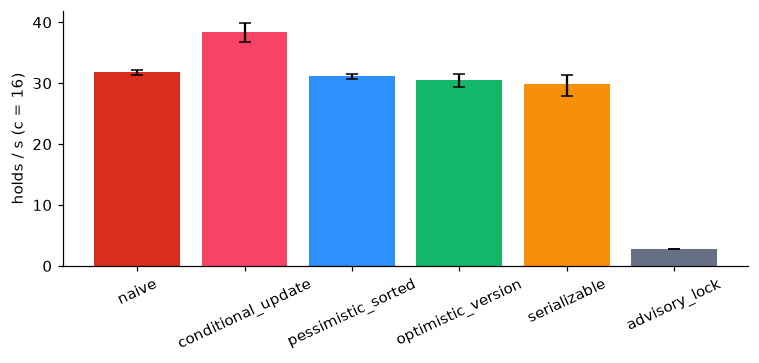

In [7]:
t16 = thr[thr.c == 16].set_index("strategy").reindex([s for s in ORDER if s in thr.strategy.values])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.bar(t16.index, t16.holds_per_s, yerr=[t16.holds_per_s - t16.ci_low, t16.ci_high - t16.holds_per_s], color=[COLORS[s] for s in t16.index], capsize=4)
ax.set_ylabel("holds / s (c = 16)"); ax.tick_params(axis="x", rotation=25); plt.tight_layout(); plt.show()

## Computational cost (client side and server side)

In [8]:
cells = neon[neon.type == "cell_end"].dropna(subset=["serverStats"])
srv = pd.json_normalize(cells.serverStats).assign(exp=cells.exp.values, strategy=cells.strategy.values, c=cells.c.values)
print("server-side deadlocks by cell:")
print(srv[srv.deadlocks > 0][["exp", "strategy", "c", "deadlocks"]].to_string(index=False))
print(f"\nclient memory: max RSS {T.rssMb.max():.1f} MB; median trial makespan by experiment (ms):")
T.groupby("exp").makespanMs.median().round(1)

server-side deadlocks by cell:
exp              strategy    c  deadlocks
 E2 pessimistic_unordered 16.0        101

client memory: max RSS 67.9 MB; median trial makespan by experiment (ms):


exp
E1     970.5
E2    1514.2
E3    2458.2
Name: makespanMs, dtype: float64